# 1. Importing a sample of the images

In [1]:
sample_path = '/kaggle/input/datasets/tlhalefolouw/PlantVillage Dataset/color'
path = '/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color'


## Retrieving the file directories of all the images 

In [2]:
#Package imports
import os

direc = path
folders = os.listdir(direc)

file_path = []
labels = []

for f in folders:
    fpath = os.path.join(direc, f)
    images = os.listdir(fpath)

    for i in images:
        impath = os.path.join(fpath, i)
        file_path .append(impath)
        labels.append(f)


print('Total images = ', len(file_path))
print('Totak images = ', len(labels))

Total images =  54305
Totak images =  54305


# 2. Data Preprocessing  

## Converting the directories into a pandas dataset

In [3]:
#Package imports
import pandas as pd

df1 = pd.Series(file_path, name = 'File Paths') #paths

df2 = pd.Series(labels, name = 'Labels') #labels

df = pd.concat([df1,df2], axis = 1)

In [4]:
df['File Paths'].iloc[0]

'/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color/Tomato___Late_blight/781e93a9-2059-42de-8075-658033a6abf7___RS_Late.B 6075.JPG'

## Class distribution across sample dataset

In [5]:
df.Labels.value_counts()

Labels
Orange___Haunglongbing_(Citrus_greening)              5507
Tomato___Tomato_Yellow_Leaf_Curl_Virus                5357
Soybean___healthy                                     5090
Peach___Bacterial_spot                                2297
Tomato___Bacterial_spot                               2127
Tomato___Late_blight                                  1909
Squash___Powdery_mildew                               1835
Tomato___Septoria_leaf_spot                           1771
Tomato___Spider_mites Two-spotted_spider_mite         1676
Apple___healthy                                       1645
Tomato___healthy                                      1591
Blueberry___healthy                                   1502
Pepper,_bell___healthy                                1478
Tomato___Target_Spot                                  1404
Grape___Esca_(Black_Measles)                          1383
Corn_(maize)___Common_rust_                           1192
Grape___Black_rot                                

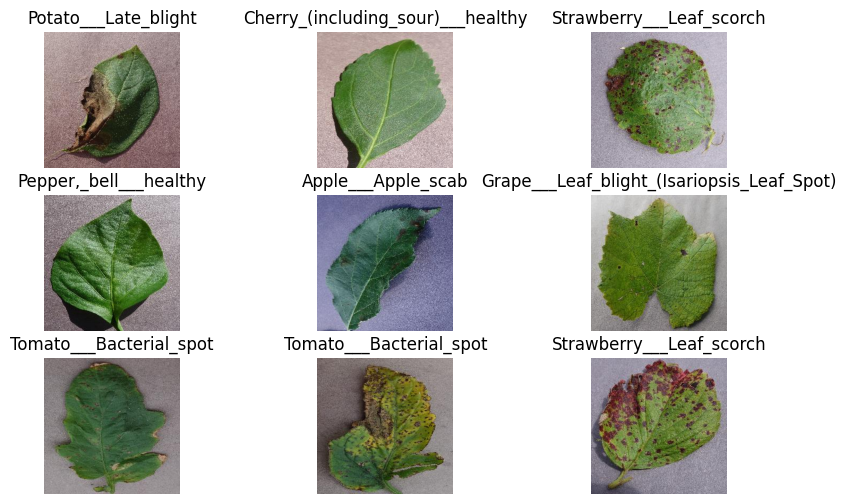

In [6]:
#Package import
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize = (10, 6))

for i in range(9):
    plt.subplot(3, 3, i+1)
    idx_arr = np.random.randint(0, len(df))
    img_path = df.iloc[idx_arr]['File Paths']

    label = df.iloc[idx_arr]['Labels']
    image = plt.imread(img_path)

    plt.imshow(image)
    plt.title(label)
    plt.axis('off')

plt.show()

In [7]:
Labels_sum = df.Labels.value_counts().reset_index()
Labels_sum.columns = ['Label', 'Count']

import plotly.express as px
figure = px.bar(Labels_sum,x = 'Count', y = 'Label',  color = 'Count', orientation = 'h', title = 'Class Distribution Across Dataset')

figure.update_layout(
    xaxis_title = 'Total Images per Class',
    yaxis_title = 'Classes'
)

figure.show()

In [8]:
#Package import
from sklearn.model_selection import train_test_split
train_data, tmp_data = train_test_split(
    df, 
    test_size=0.2, 
    shuffle=True, 
    stratify=df['Labels'], 
    random_state=42)

validation_data, test_data = train_test_split(
    tmp_data, 
    test_size=0.5, 
    shuffle=True, 
    stratify=tmp_data['Labels'], 
    random_state=42)

In [9]:
print(len(train_data.Labels.value_counts()))
print(len(test_data.Labels.value_counts()))
print(len(validation_data.Labels.value_counts()))

38
38
38


In [10]:
plt.imread(file_path[0]).shape

(256, 256, 3)

In [11]:
img_size = (224, 224)
batch_size = 32
channels = 3

In [12]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

trainDatagen = ImageDataGenerator(
    rescale = 1./255,
    rotation_range = 45,
    width_shift_range = 0.2,
    height_shift_range = 0.2,
    shear_range = 0.2,
    zoom_range = 0.2,
    horizontal_flip = True,
    fill_mode = 'nearest'
)

testDatagen=ImageDataGenerator(rescale = 1./255,)

In [13]:
trainGen = trainDatagen.flow_from_dataframe(
    dataframe = train_data,
    x_col = 'File Paths',
    y_col = 'Labels',
    target_size = (img_size),
    batch_size = batch_size,
    class_mode = 'categorical',
    shuffle = False)

Found 43444 validated image filenames belonging to 38 classes.


In [14]:
testGen = testDatagen.flow_from_dataframe(
    dataframe = test_data,
    x_col = 'File Paths',
    y_col = 'Labels',
    target_size = (img_size),
    batch_size = batch_size,
    class_mode = 'categorical',
    shuffle = False)

Found 5431 validated image filenames belonging to 38 classes.


In [15]:
validationGen = testDatagen.flow_from_dataframe(
    dataframe = validation_data,
    x_col = 'File Paths',
    y_col = 'Labels',
    target_size = (img_size),
    batch_size = batch_size,
    class_mode = 'categorical',
    shuffle = False)

Found 5430 validated image filenames belonging to 38 classes.


# 3. Model Development

## Model Layers


In [16]:
#Package import
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, ReLU, MaxPooling2D, Dropout

model = Sequential([
    Conv2D(32,(3,3),activation='relu',padding='same',input_shape=(224, 224,channels)),
    Conv2D(64,(3,3),activation='relu',padding='same'),
    MaxPooling2D((2,2)),

    Conv2D(64,(3,3),activation='relu',padding='same'),
    Conv2D(64,(3,3),activation='relu',padding='same'),
    MaxPooling2D((2,2)),
    
    Conv2D(128,(3,3),activation='relu',padding='same'),
    Conv2D(128,(3,3),activation='relu',padding='same'),
    MaxPooling2D((2,2)),
    Dropout(0.2),

    Flatten(),
    Dense(256,activation='relu'),
    Dense(128,activation='relu'),
    Dropout(0.5),
    Dense(len(trainGen.class_indices),activation='softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.

I0000 00:00:1790017961.565505      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790017961.568329      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## Model Optimizer

In [17]:
from tensorflow.keras.optimizers import Adam 

model.compile(
    optimizer = Adam(learning_rate = 0.001),
    loss = 'categorical_crossentropy',
    metrics = ['accuracy']
)

In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,042,854 (99.35 MB)

 Trainable params: 26,042,854 (99.35 MB)

 Non-trainable params: 0 (0.00 B)

## Model Training Callbacks

In [19]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks = [
    EarlyStopping(patience=4, 
    restore_best_weights=True, 
    monitor='val_loss', 
    verbose=1),
    
    ReduceLROnPlateau(
        factor=0.3, 
        patience=2, 
        monitor='val_loss', 
        verbose=1),
    
    ModelCheckpoint(
        "Best_Model.h5", 
        monitor ='val_loss', 
        save_best_only=True, 
        verbose=1)]

## Model Training

In [20]:
history=model.fit(
    trainGen,
    epochs=25,
    validation_data=validationGen,
    callbacks=callbacks, 
    verbose=1)

Epoch 1/25


2026-09-21 19:12:55.760272: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 19:12:55.914803: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1790017984.097737      75 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 914/1358 ━━━━━━━━━━━━━━━━━━━━ 5:11 702ms/step - accuracy: 0.1829 - loss: 3.0956

2026-09-21 19:23:49.992081: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 19:23:50.145110: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 741ms/step - accuracy: 0.2200 - loss: 2.9334
Epoch 1: val_loss improved from None to 1.64667, saving model to Best_Model.h5



Epoch 1: finished saving model to Best_Model.h5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1100s 796ms/step - accuracy: 0.3242 - loss: 2.4878 - val_accuracy: 0.5254 - val_loss: 1.6467 - learning_rate: 0.0010
Epoch 2/25
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 550ms/step - accuracy: 0.5186 - loss: 1.6741
Epoch 2: val_loss improved from 1.64667 to 1.06004, saving model to Best_Model.h5


... (13 outputs left out)


Epoch 20: finished saving model to Best_Model.h5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 687s 506ms/step - accuracy: 0.9528 - loss: 0.1498 - val_accuracy: 0.9707 - val_loss: 0.0923 - learning_rate: 3.0000e-04
Epoch 21/25
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 475ms/step - accuracy: 0.9556 - loss: 0.1455
Epoch 21: val_loss improved from 0.09231 to 0.07704, saving model to Best_Model.h5



Epoch 21: finished saving model to Best_Model.h5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 667s 491ms/step - accuracy: 0.9561 - loss: 0.1450 - val_accuracy: 0.9738 - val_loss: 0.0770 - learning_rate: 3.0000e-04
Epoch 22/25
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - accuracy: 0.9585 - loss: 0.1339
Epoch 22: val_loss did not improve from 0.07704
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 673s 496ms/step - accuracy: 0.9583 - loss: 0.1356 - val_accuracy: 0.9617 - val_loss: 0.1051 - learning_rate: 3.0000e-04
Epoch 23/25
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 539ms/step - accuracy: 0.9573 - loss: 0.1383
Epoch 23: val_loss improved from 0.07704 to 0.07469, saving model to Best_Model.h5



Epoch 23: finished saving model to Best_Model.h5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 760s 560ms/step - accuracy: 0.9584 - loss: 0.1368 - val_accuracy: 0.9764 - val_loss: 0.0747 - learning_rate: 3.0000e-04
Epoch 24/25
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.9600 - loss: 0.1252
Epoch 24: val_loss did not improve from 0.07469
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 703s 517ms/step - accuracy: 0.9590 - loss: 0.1276 - val_accuracy: 0.9744 - val_loss: 0.0847 - learning_rate: 3.0000e-04
Epoch 25/25
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - accuracy: 0.9632 - loss: 0.1191
Epoch 25: val_loss improved from 0.07469 to 0.06837, saving model to Best_Model.h5



Epoch 25: finished saving model to Best_Model.h5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 673s 495ms/step - accuracy: 0.9627 - loss: 0.1199 - val_accuracy: 0.9796 - val_loss: 0.0684 - learning_rate: 3.0000e-04
Restoring model weights from the end of the best epoch: 25.


## Model Evaluation

In [21]:
lossTrain,accuracyTrain = model.evaluate(trainGen)

lossValid,accuracyValid = model.evaluate(validationGen)

lossTest,accuracyTest = model.evaluate(testGen)

1358/1358 ━━━━━━━━━━━━━━━━━━━━ 651s 479ms/step - accuracy: 0.9740 - loss: 0.0815
170/170 ━━━━━━━━━━━━━━━━━━━━ 24s 144ms/step - accuracy: 0.9796 - loss: 0.0684
170/170 ━━━━━━━━━━━━━━━━━━━━ 82s 487ms/step - accuracy: 0.9801 - loss: 0.0680


In [22]:
print(f'Training Loss: {lossTrain}, Train Accuracy: {accuracyTrain}')

print(f'Validation Loss : {lossValid},Accuracy Valid: {accuracyValid}')

print(f'Testing Loss : {lossTest},Testing Accuracy : {accuracyTest}')

Training Loss: 0.08145258575677872, Train Accuracy: 0.9740355610847473
Validation Loss : 0.06837213039398193,Accuracy Valid: 0.979557991027832
Testing Loss : 0.0679761990904808,Testing Accuracy : 0.9801141619682312


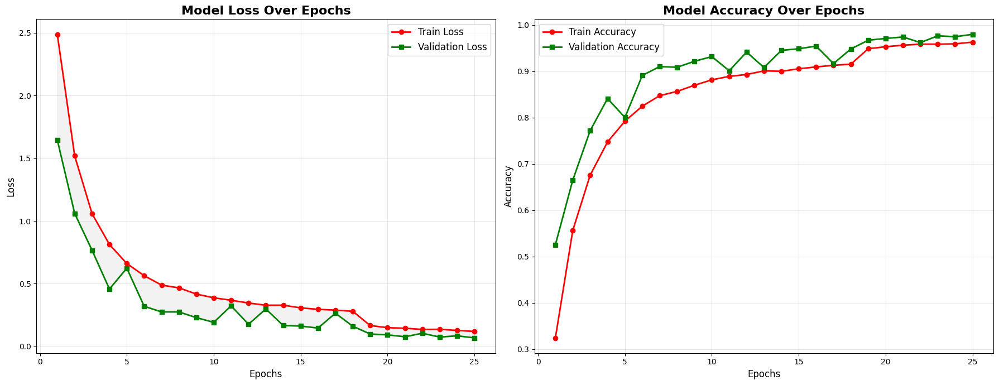

In [23]:
train_acc = history.history['accuracy']
train_loss = history.history['loss']
validation_acc = history.history['val_accuracy']
validation_loss = history.history['val_loss']

epochs = np.arange(1, len(train_acc) + 1)

plt.figure(figsize=(18, 7))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, color= 'red', linewidth=2, marker='o', label='Train Loss')
plt.plot(epochs, validation_loss, color='green', linewidth=2, marker='s', label='Validation Loss')
plt.fill_between(epochs, validation_loss, train_loss, color='gray', alpha=0.1)

plt.title('Model Loss Over Epochs', fontsize=16, weight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(alpha=0.3)
plt.legend(fontsize=12)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_acc, color='red', linewidth=2, marker='o', label='Train Accuracy')
plt.plot(epochs, validation_acc, color='green', linewidth=2, marker='s', label='Validation Accuracy')
plt.title('Model Accuracy Over Epochs', fontsize=16, weight='bold')  
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.grid(alpha=0.3)
plt.legend(fontsize=12)


plt.tight_layout()
plt.show()

# 4. Model Predictions

In [24]:
from PIL import Image

def preprocess(img_path, target_size=(224, 224)):
    img = Image.open(img_path)
    resized = img.resize(target_size)
    img_arr = np.array(resized)
    img_arr = np.expand_dims(img_arr, axis=0)
    img_arr = img_arr.astype('float32') / 255.
    return img_arr

In [25]:
from sklearn.metrics import confusion_matrix, classification_report

def prediction(model,img_path,class_indices):
  preprocessed_img = preprocess(img_path)
  predictions = model.predict(preprocessed_img)
  predicted_class_index = np.argmax(predictions, axis=1)[0]
  predicted_class_name = class_indices[predicted_class_index]
    
  return predicted_class_name

In [26]:
class_indices = {a: b for b, a in trainGen.class_indices.items()}
class_indices

{0: 'Apple___Apple_scab',
 1: 'Apple___Black_rot',
 2: 'Apple___Cedar_apple_rust',
 3: 'Apple___healthy',
 4: 'Blueberry___healthy',
 5: 'Cherry_(including_sour)___Powdery_mildew',
 6: 'Cherry_(including_sour)___healthy',
 7: 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 8: 'Corn_(maize)___Common_rust_',
 9: 'Corn_(maize)___Northern_Leaf_Blight',
 10: 'Corn_(maize)___healthy',
 11: 'Grape___Black_rot',
 12: 'Grape___Esca_(Black_Measles)',
 13: 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 14: 'Grape___healthy',
 15: 'Orange___Haunglongbing_(Citrus_greening)',
 16: 'Peach___Bacterial_spot',
 17: 'Peach___healthy',
 18: 'Pepper,_bell___Bacterial_spot',
 19: 'Pepper,_bell___healthy',
 20: 'Potato___Early_blight',
 21: 'Potato___Late_blight',
 22: 'Potato___healthy',
 23: 'Raspberry___healthy',
 24: 'Soybean___healthy',
 25: 'Squash___Powdery_mildew',
 26: 'Strawberry___Leaf_scorch',
 27: 'Strawberry___healthy',
 28: 'Tomato___Bacterial_spot',
 29: 'Tomato___Early_blight',
 30: '

## Sample Image Prediction


In [27]:
image_path = '/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color/Apple___healthy/0055dd26-23a7-4415-ac61-e0b44ebfaf80___RS_HL 5672.JPG'
predicted_class_name = prediction(model, image_path, class_indices)

print("Predicted Class Name:", predicted_class_name)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Class Name: Apple___healthy


## Visual Image Predictions

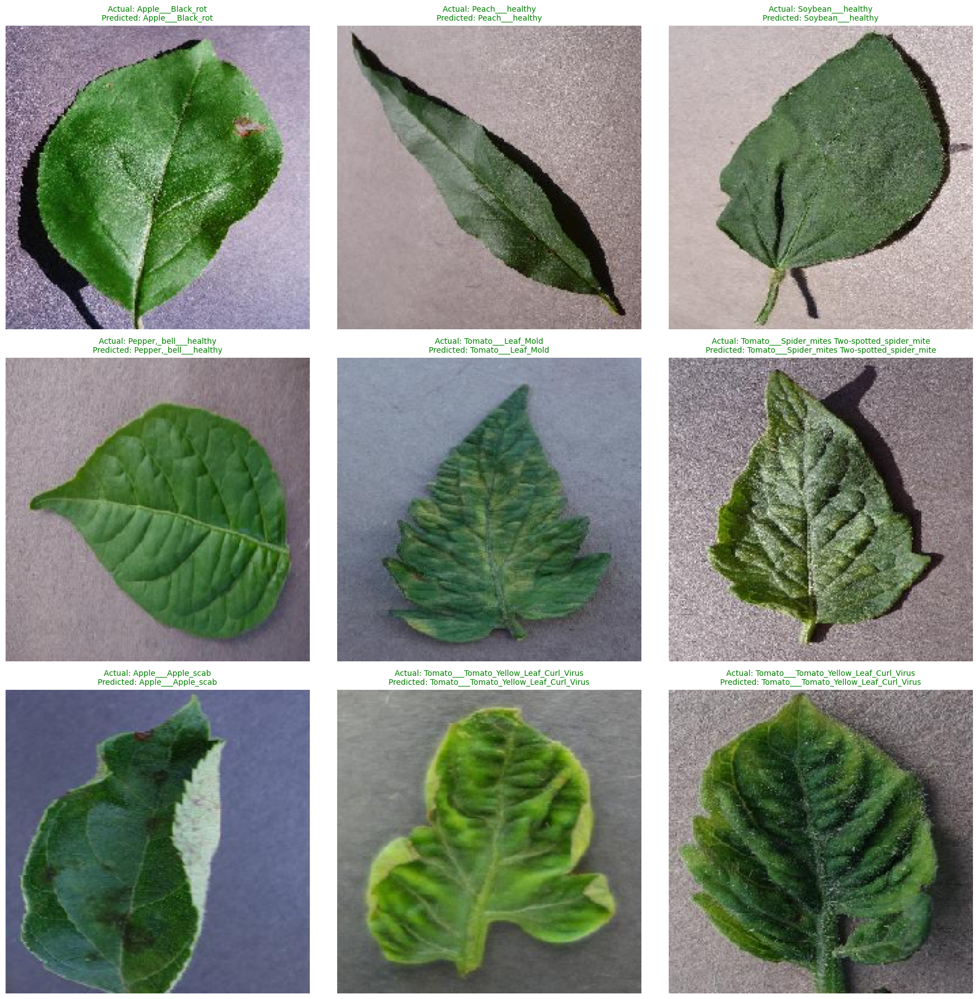

In [28]:
plt.figure(figsize=(18,18))

images, labels = next(testGen)

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    plt.axis('off')

    true_label_idx = np.argmax(labels[i])
    actual = class_indices[true_label_idx]

    preds = model.predict(np.expand_dims(images[i], axis=0), verbose=0)
    pred_label_idx = np.argmax(preds)
    predict = class_indices[pred_label_idx]

    color = 'green' if actual == predict else 'red'  
    plt.title(f"Actual: {actual}\nPredicted: {predict}", color=color, fontsize=10)

plt.tight_layout()
plt.show()

## Confusion Matrix & Classification Report

170/170 ━━━━━━━━━━━━━━━━━━━━ 18s 101ms/step


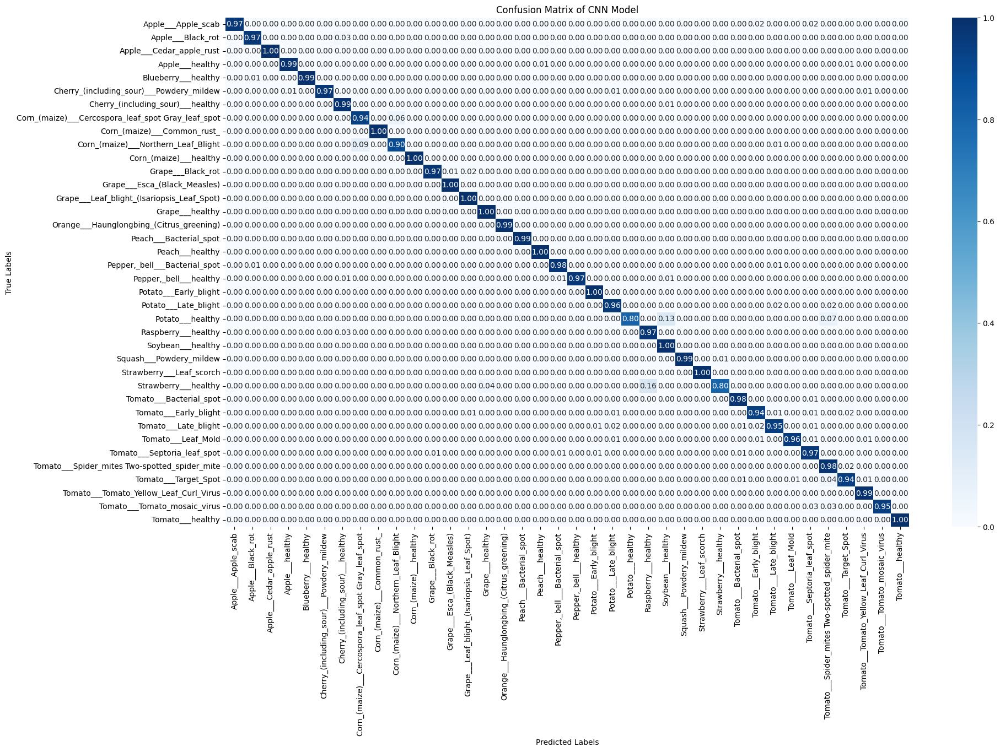


Classification Report:

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      0.97      0.98        63
                                 Apple___Black_rot       0.97      0.97      0.97        62
                          Apple___Cedar_apple_rust       1.00      1.00      1.00        27
                                   Apple___healthy       0.98      0.99      0.98       165
                               Blueberry___healthy       1.00      0.99      1.00       150
          Cherry_(including_sour)___Powdery_mildew       0.98      0.97      0.98       105
                 Cherry_(including_sour)___healthy       0.95      0.99      0.97        85
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.84      0.94      0.89        51
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       120
               Corn_(maize)___Northern_Leaf_Blight    

In [29]:
import seaborn as sns

y_true = testGen.classes

y_pred = model.predict(testGen, verbose=1)
y_pred_classes = np.argmax(y_pred, axis=1)

conmatr = confusion_matrix(y_true, y_pred_classes,normalize='true')

class_names = list(testGen.class_indices.keys())

plt.figure(figsize=(20, 12))
sns.heatmap(conmatr, annot=True, cmap='Blues', fmt='.2f',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix of CNN Model')
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred_classes, target_names=class_names))

# 5. GRAD-CAM Development

## GRAD-CAM Heatmaps Functions

In [30]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

last_conv_layer = model.layers[7]

print("Grad-CAM layer:", last_conv_layer.name)



Grad-CAM layer: conv2d_5


In [31]:
def make_gradcam_heatmap(img_array, model, last_conv_layer, pred_index=None):

    #Input tensor
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = inputs

    for layer in model.layers:
        x = layer(x)

        if layer.name == last_conv_layer.name:
            conv_output = x

    predictions = x

    grad_model = tf.keras.models.Model(
        inputs=inputs,
        outputs=[conv_output, predictions]
    )

    with tf.GradientTape() as tape:

        conv_output, preds = grad_model(img_array)

        if pred_index is None:
            pred_index = tf.argmax(preds[0])

        class_channel = preds[:, pred_index]

    grads = tape.gradient(
        class_channel,
        conv_output
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_output = conv_output[0]

    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0)
    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return heatmap.numpy(), preds.numpy()
    

   

In [32]:
#Package IMports
import matplotlib.cm as cm

def gradCAMImage(image_path):

    img = load_img(image_path, target_size=(224, 224))

    img_array = img_to_array(img)
    original_img = img_array.copy()
    img_array = img_array.astype('float32') / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    heatmap, preds = make_gradcam_heatmap(img_array, model, last_conv_layer)
    
    predicted_class_index = np.argmax(preds[0])
    predicted_class = class_indices[predicted_class_index]

    heatmap = np.uint8(255 * heatmap)

    jet = cm.get_cmap("jet")

    jet_colors = jet(np.arange(256))[:, :3]

    jet_heatmap = jet_colors[heatmap]
    jet_heatmap = tf.keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((original_img.shape[1], original_img.shape[0]))
    jet_heatmap = tf.keras.preprocessing.image.img_to_array(jet_heatmap)

    superimposed_img = (jet_heatmap * 0.4 + original_img * 0.6)
    superimposed_img = np.clip(superimposed_img, 0,255).astype('uint8')
    superimposed_img = tf.keras.preprocessing.image.array_to_img(superimposed_img)

    return superimposed_img, predicted_class

In [33]:
def gradcam_of_images(correct_class=True, number_of_images=15):

    grad_images = []
    titles = []
    temp_df = test_data.copy().reset_index(drop=True)

    for i in range(len(temp_df)):

        image_path = temp_df['File Paths'].iloc[i]
        actual = temp_df['Labels'].iloc[i]
        preprocessed_img = preprocess(image_path)

        prediction_output = model.predict(preprocessed_img, verbose=0)
        predicted_index = np.argmax(prediction_output[0])
        predicted = class_indices[predicted_index]

        is_correct = actual == predicted

        if is_correct == correct_class:

            grad_image, predicted_class = gradCAMImage(image_path)
            grad_images.append(grad_image)
            titles.append( f"Actual: {actual}\nPredicted: {predicted}")

        if len(grad_images) >= number_of_images:
            break

    return grad_images, titles

In [34]:
def display_heatmaps(classified_images, titles):

    number_of_images = len(classified_images)

    if number_of_images == 0:
        print("No images found for this category.")
        return

    columns = 5
    rows = int(np.ceil(number_of_images / columns))

    plt.figure(figsize=(20, 4 * rows))

    for i in range(number_of_images):
        plt.subplot(rows, columns, i + 1)
        plt.imshow(classified_images[i])
        plt.title(titles[i],fontsize=10)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

## Grad Visual Samples

/tmp/ipykernel_23/3996620996.py:20: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



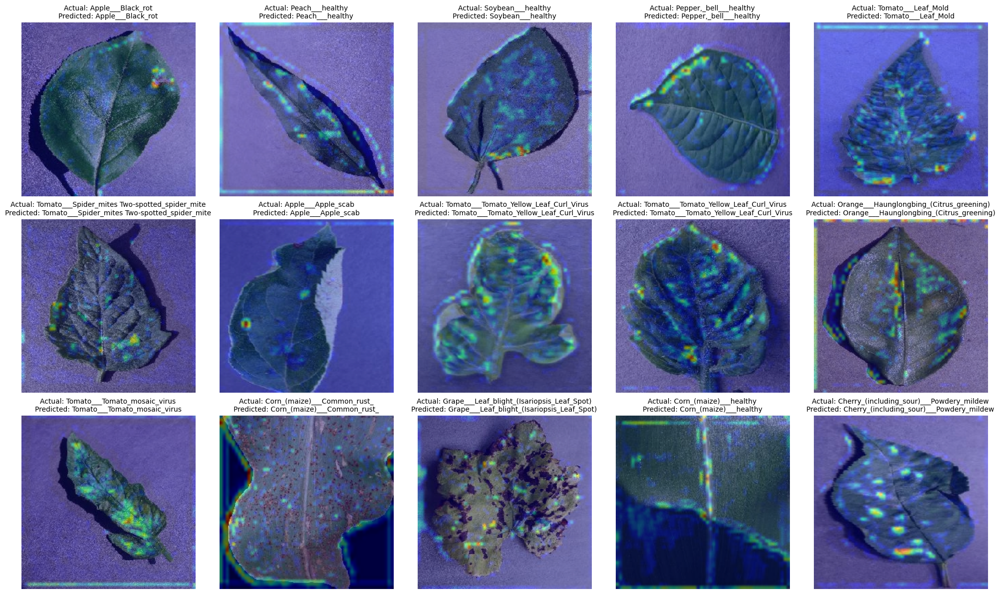

In [35]:

correctly_classified, c_titles = gradcam_of_images(
    correct_class=True,
    number_of_images=15
)

display_heatmaps(
    correctly_classified,
    c_titles
)

/tmp/ipykernel_23/3996620996.py:20: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



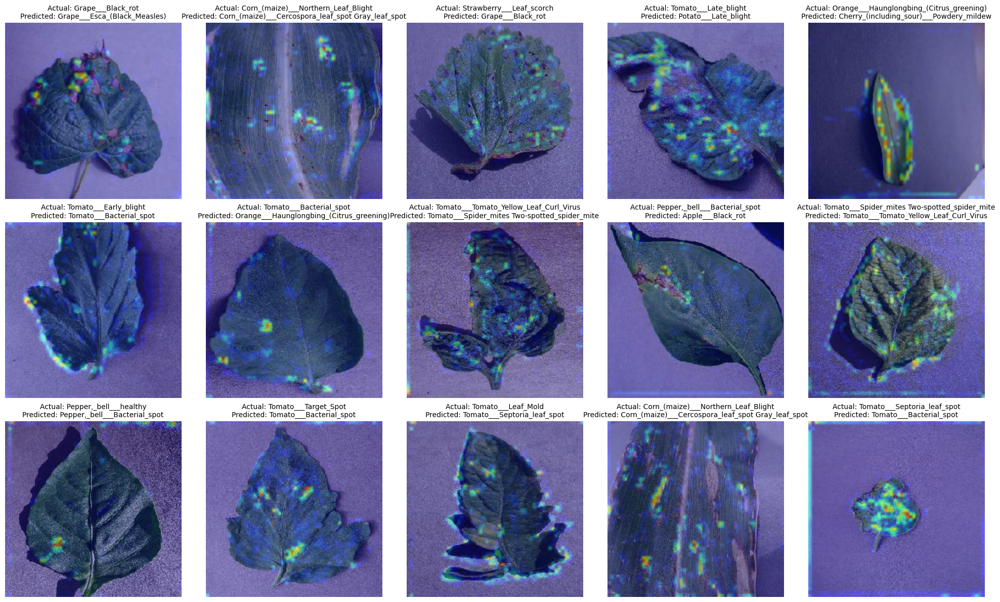

In [36]:
misclassified, m_titles = gradcam_of_images(
    correct_class=False,
    number_of_images=15
)

display_heatmaps(
    misclassified,
    m_titles
)